# hoefflin2026spatial: cell type annotation analysis

Standalone analysis of **hoefflin2026spatial**, the only one of the three locally downloaded datasets with `metadata/cells.parquet`. Includes cohort and metadata quality, channel coverage, image inventory, CODEX previews, cell counts and composition, and an H&E cell type overlay using supplied instance masks.

Run from top to bottom with Python 3.11+ and `numpy pandas pyarrow matplotlib zarr>=3 nbformat ipykernel openpyxl`. Data are read from the existing REQ-82797 download; no source data are modified. H&E figures are saved under result/figures/; tables under result/.

Tissues and patients are counted uniquely. Clinical metadata repeated across modalities are deduplicated. Field area is rectangular image area, not segmented tissue area. Cell types are supplied annotations, not predictions from H&E. Spatial alignment relies on the supplied `exact` metadata, with no new registration.


In [1]:
from pathlib import Path
import json
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import zarr
assert int(zarr.__version__.split(".")[0]) >= 3, "OME-Zarr v3 images require zarr>=3 (Python 3.11+)"
from IPython.display import display

DATA_ROOT = Path('/lustre/scratch127/cellgen/cellgeni/tickets/REQ-82797/data')
hoefflin_DATASETS = ['hoefflin2026spatial']
hoefflin_ROOTS = {name: DATA_ROOT / name / name for name in hoefflin_DATASETS}
assert all(p.is_dir() for p in hoefflin_ROOTS.values()), 'Check DATA_ROOT and nested dataset folders'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print({package: importlib.metadata.version(package) for package in ['numpy', 'pandas', 'pyarrow', 'matplotlib', 'zarr']})
hoefflin_tables = {}
for name, root in hoefflin_ROOTS.items():
    hoefflin_tables[name] = {
        'tissues': pd.read_parquet(root / 'metadata/tissues.parquet'),
        'channels': pd.read_parquet(root / 'codex/channels.parquet'),
        'availability': pd.read_parquet(root / 'codex/channels_per_tissue.parquet'),
    }
    print(f'\n{name}')
    for kind, frame in hoefflin_tables[name].items():
        print(f'{kind}: {frame.shape}; index={frame.index.name}')
        display(frame.head(3))

{'numpy': '2.4.6', 'pandas': '2.3.3', 'pyarrow': '25.0.0', 'matplotlib': '3.11.2', 'zarr': '3.1.6'}

hoefflin2026spatial
tissues: (60, 19); index=None


,dataset,patient_id,specimen_id,tissue_id,original_patient_identifier,modality,alignment,split,SampleID,PatientID,GliomaType,GradeTumor,GradeSection,Location,Sex,Age,Visium,CODEX,IDH_status
0,hoefflin2026spatial,pdeyugcu,0,hoefflin2026spatial_pdeyugcu_0000,P6,codex,exact,train,IDHA07,P6,IDH_A,3,3,left frontal,M,23,1,1,IDH-mut
1,hoefflin2026spatial,pdeyugcu,0,hoefflin2026spatial_pdeyugcu_0000,P6,he,exact,train,IDHA07,P6,IDH_A,3,3,left frontal,M,23,1,1,IDH-mut
2,hoefflin2026spatial,kepmlucv,0,hoefflin2026spatial_kepmlucv_0000,P7,codex,exact,test,IDHA09,P7,IDH_A,4,4,left parietal,F,30,1,1,IDH-mut


channels: (70, 5); index=None


,channel_name,uniprot_id,qc_pass,description,is_nuclear_marker
0,DAPI,None,True,None,True
1,CD69,Q07108,True,None,False
2,CD45,P08575,True,None,False


availability: (31, 70); index=tissue_id


,DAPI,CD69,CD45,CD3,Ki67,CD90,CD11c,MHCII,CD8,CD4,...,HPLN1,HSPG2,TNR,DCXv2,SOX9,FLT1,PTPRZ1,ATRX,ACAN,PLP1
tissue_id,,,,,,,,,,,,,,,,,,,,,
hoefflin2026spatial_pdeyugcu_0000,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
hoefflin2026spatial_kepmlucv_0000,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
hoefflin2026spatial_otmxztix_0000,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True


## Cohort, modality pairing, and metadata quality


,cell_annotations_available,metadata_rows,patients,tissues,codex_tissues,he_tissues,paired_tissues,panel_channels,qc_pass_channels,nuclear_channels,channel_table_tissues,median_available_channels
dataset,,,,,,,,,,,,
hoefflin2026spatial,True,60,25,30,30,30,30,70,70,1,31,70.0


,duplicate_tissue_modality_rows,missing_tissue_ids,missing_patient_ids,tissues_with_multiple_splits,patients_with_multiple_splits,duplicated_channel_names,duplicate_channel_table_tissue_ids
dataset,,,,,,,
hoefflin2026spatial,0,0,0,0,0,0,0


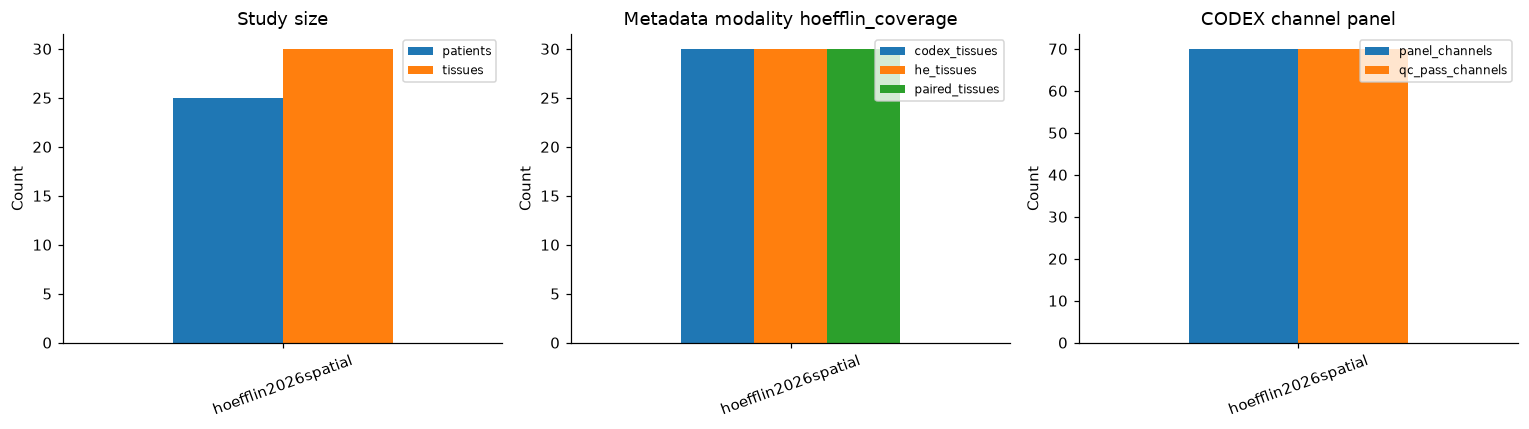


hoefflin2026spatial: missing metadata (%)


,missing_percent
dataset,0.0
patient_id,0.0
specimen_id,0.0
tissue_id,0.0
original_patient_identifier,0.0
modality,0.0
alignment,0.0
split,0.0
SampleID,0.0
PatientID,0.0


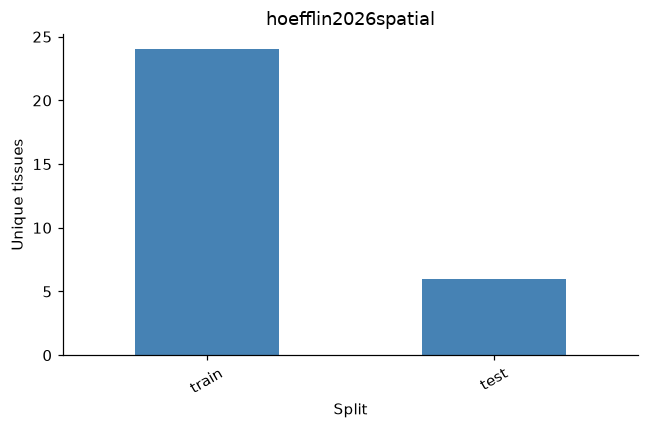

In [2]:
hoefflin_summary_rows, hoefflin_quality_rows = [], []
for name, data in hoefflin_tables.items():
    t, ch, av = data['tissues'], data['channels'], data['availability']
    modalities = t.groupby('tissue_id')['modality'].agg(set)
    hoefflin_summary_rows.append(dict(
        dataset=name, metadata_rows=len(t), patients=t.patient_id.nunique(),
        tissues=t.tissue_id.nunique(), codex_tissues=t.loc[t.modality.eq('codex'), 'tissue_id'].nunique(),
        he_tissues=t.loc[t.modality.eq('he'), 'tissue_id'].nunique(),
        paired_tissues=sum({'codex', 'he'}.issubset(x) for x in modalities),
        panel_channels=len(ch), qc_pass_channels=int(ch.qc_pass.fillna(False).sum()),
        nuclear_channels=int(ch.is_nuclear_marker.fillna(False).sum()),
        channel_table_tissues=len(av), median_available_channels=av.fillna(False).sum(axis=1).median(),
        cell_annotations_available=(hoefflin_ROOTS[name] / 'metadata/cells.parquet').exists()))
    hoefflin_quality_rows.append(dict(dataset=name,
        duplicate_tissue_modality_rows=int(t.duplicated(['tissue_id', 'modality']).sum()),
        missing_tissue_ids=int(t.tissue_id.isna().sum()), missing_patient_ids=int(t.patient_id.isna().sum()),
        tissues_with_multiple_splits=int((t.groupby('tissue_id').split.nunique() > 1).sum()),
        patients_with_multiple_splits=int((t.groupby('patient_id').split.nunique() > 1).sum()),
        duplicated_channel_names=int(ch.channel_name.duplicated().sum()),
        duplicate_channel_table_tissue_ids=int(av.index.duplicated().sum())))
hoefflin_summary = pd.DataFrame(hoefflin_summary_rows).set_index('dataset')
hoefflin_summary = hoefflin_summary[['cell_annotations_available'] + [col for col in hoefflin_summary.columns if col != 'cell_annotations_available']]
display(hoefflin_summary)
display(pd.DataFrame(hoefflin_quality_rows).set_index('dataset'))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, cols, title in zip(axes,
    [['patients', 'tissues'], ['codex_tissues', 'he_tissues', 'paired_tissues'], ['panel_channels', 'qc_pass_channels']],
    ['Study size', 'Metadata modality hoefflin_coverage', 'CODEX channel panel']):
    hoefflin_summary[cols].plot.bar(ax=ax, rot=20)
    ax.set(title=title, xlabel='', ylabel='Count')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 1, figsize=(6, 4))
axes = np.atleast_1d(axes)
for ax, (name, data) in zip(axes, hoefflin_tables.items()):
    t = data['tissues']
    tissue_split = t.drop_duplicates('tissue_id')['split'].fillna('(missing)').value_counts()
    tissue_split.plot.bar(ax=ax, color='steelblue', rot=30)
    ax.set(title=name, xlabel='Split', ylabel='Unique tissues')
    print(f'\n{name}: missing metadata (%)')
    display(t.isna().mean().mul(100).sort_values(ascending=False).rename('missing_percent').to_frame())
plt.tight_layout()
plt.show()

In [3]:
hoefflin_tissues = hoefflin_tables['hoefflin2026spatial']['tissues']
hoefflin_unique_tissues = hoefflin_tissues.drop_duplicates('tissue_id')
print('Unique tissues per patient:')
display(hoefflin_unique_tissues.groupby('patient_id').size().rename('tissues').describe().to_frame())
print('Patient counts per split (patients can appear in multiple splits; see quality checks):')
display(hoefflin_tissues[['patient_id', 'split']].drop_duplicates().groupby('split', dropna=False).patient_id.nunique().rename('patients').to_frame())
print('Metadata values per field (unique tissue rows; missing values included):')
for hoefflin_field in hoefflin_unique_tissues.columns:
    if hoefflin_field not in ['tissue_id', 'patient_id', 'modality'] and hoefflin_unique_tissues[hoefflin_field].nunique() <= 30:
        display(hoefflin_unique_tissues[hoefflin_field].value_counts(dropna=False).rename('tissues').to_frame().rename_axis(hoefflin_field))

from pathlib import Path
# One row per tissue; retain multiple tissues belonging to the same patient.
hoefflin_metadata_fields = [c for c in hoefflin_tissues.columns if c != 'modality']
hoefflin_metadata_conflicts = hoefflin_tissues.groupby('tissue_id')[hoefflin_metadata_fields].nunique(dropna=False).gt(1)
assert not hoefflin_metadata_conflicts.any().any(), 'Conflicting metadata across modalities; review before export.'
hoefflin_tissue_metadata = hoefflin_tissues[hoefflin_metadata_fields].drop_duplicates('tissue_id').copy()
hoefflin_modalities = hoefflin_tissues.groupby('tissue_id')['modality'].agg(lambda values: ', '.join(sorted(set(values.dropna().astype(str)))))
hoefflin_tissue_metadata['modality'] = hoefflin_tissue_metadata['tissue_id'].map(hoefflin_modalities)
hoefflin_column_order = ['tissue_id', 'patient_id'] + [c for c in hoefflin_tissues.columns if c not in ['tissue_id', 'patient_id']]
hoefflin_tissue_metadata = hoefflin_tissue_metadata[hoefflin_column_order].sort_values(['patient_id', 'tissue_id']).reset_index(drop=True)
hoefflin_result_dir = Path('/lustre/scratch124/cellgen/bayraktar/ll20/project/Embryo_Hist2Pheno/toturial/spora/result')
hoefflin_result_dir.mkdir(parents=True, exist_ok=True)
hoefflin_excel_path = hoefflin_result_dir / 'hoefflin2026spatial_tissue_metadata.xlsx'
with pd.ExcelWriter(hoefflin_excel_path, engine='openpyxl') as hoefflin_writer:
    hoefflin_tissue_metadata.to_excel(hoefflin_writer, sheet_name='tissue_metadata', index=False)
    hoefflin_sheet = hoefflin_writer.sheets['tissue_metadata']
    hoefflin_sheet.freeze_panes = 'C2'
    hoefflin_sheet.auto_filter.ref = hoefflin_sheet.dimensions
    for hoefflin_col in hoefflin_sheet.columns:
        hoefflin_sheet.column_dimensions[hoefflin_col[0].column_letter].width = min(55, max(12, max(len(str(cell.value)) if cell.value is not None else 0 for cell in hoefflin_col) + 2))
print(f'Saved {len(hoefflin_tissue_metadata)} tissues from {hoefflin_tissue_metadata.patient_id.nunique()} patients: {hoefflin_excel_path}')


Unique tissues per patient:


,tissues
count,25.000000
mean,1.200000
std,0.408248
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,2.000000


Patient counts per split (patients can appear in multiple splits; see quality checks):


,patients
split,
test,5
train,20


Metadata values per field (unique tissue rows; missing values included):


,tissues
dataset,
hoefflin2026spatial,30


... (11 outputs left out)

,tissues
Age,
30,4
36,3
48,2
47,2
54,2
27,2
24,2
62,2
23,1


,tissues
Visium,
1,21
0,9


,tissues
CODEX,
1,30


,tissues
IDH_status,
IDH-mut,30


## Channel panel and tissue coverage
Presence and panel QC are reported separately. Missing availability values count as unavailable.


,channel_name,uniprot_id,qc_pass,description,is_nuclear_marker,available_fraction
68,ACAN,P16112,True,Should be P16112 but was disabled due to ESM2 ...,False,1.0
35,APOD,P05090,True,None,False,1.0
34,APOE,P02649,True,None,False,1.0
23,AQP4,P55087,True,None,False,1.0
67,ATRX,P46100,True,None,False,1.0
...,...,...,...,...,...,...
62,TNR,Q92752,True,None,False,1.0
54,TUBB3,Q13509,True,None,False,1.0
55,VCAN,P13611,True,None,False,1.0
14,VIM,P08670,True,None,False,1.0


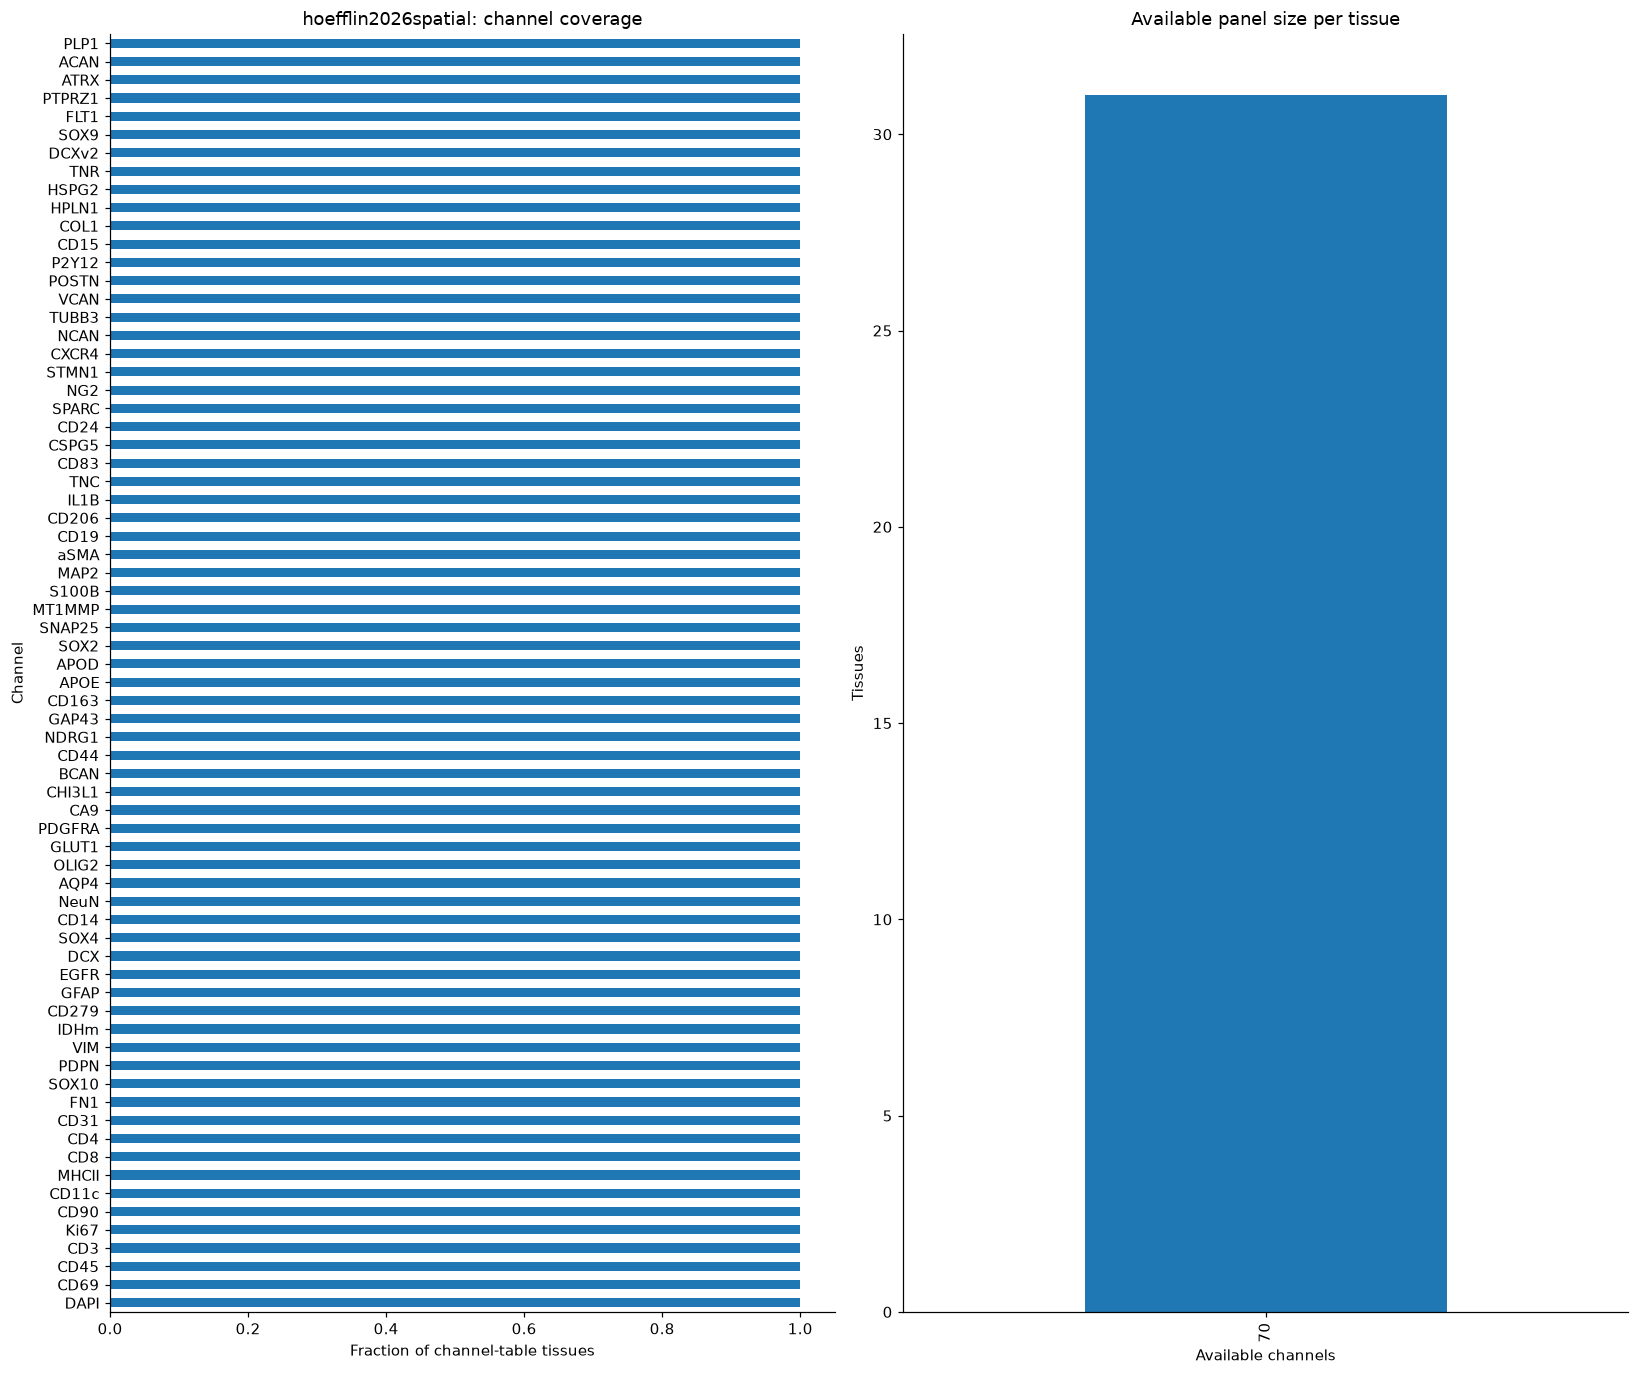

In [4]:
hoefflin_channels = hoefflin_tables['hoefflin2026spatial']['channels'].copy()
hoefflin_availability = hoefflin_tables['hoefflin2026spatial']['availability'].fillna(False)
hoefflin_channel_coverage = hoefflin_availability.mean().rename('available_fraction')
display(hoefflin_channels.merge(hoefflin_channel_coverage, left_on='channel_name', right_index=True, how='outer'))
fig, axes = plt.subplots(1, 2, figsize=(15, max(5, len(hoefflin_channel_coverage)*0.18)))
hoefflin_channel_coverage.sort_values().plot.barh(ax=axes[0])
axes[0].set(xlabel='Fraction of channel-table tissues', ylabel='Channel', title='hoefflin2026spatial: channel coverage', xlim=(0, 1.05))
hoefflin_availability.sum(axis=1).value_counts().sort_index().plot.bar(ax=axes[1])
axes[1].set(xlabel='Available channels', ylabel='Tissues', title='Available panel size per tissue')
plt.tight_layout()
plt.show()


## Local image inventory, pairing, and dimensions


,dataset,modality,resolution,stores
0,hoefflin2026spatial,codex,0_5mpp,30
1,hoefflin2026spatial,codex,1_0mpp,30
2,hoefflin2026spatial,he,0_5mpp,30
3,hoefflin2026spatial,he,1_0mpp,30


height                width                 \
                                min  median    max   min  median    max   
dataset             modality                                              
hoefflin2026spatial codex      3504  8856.0  14592  3152  7048.0  16608   
                    he         3504  8856.0  14592  3152  7048.0  16608   

                             channels            field_area_mm2             \
                                  min median max            min     median   
dataset             modality                                                 
hoefflin2026spatial codex          70   70.0  70      11.044608  64.998891   
                    he              3    3.0   3      11.044608  64.998891   

                                        uncompressed_GiB                       
                                    max              min    median        max  
dataset             modality                                                   
hoefflin2026spatial codex     184.18272         1.440053  8.474891  24.014693  
                    he        184.18272         0.030858  0.181605   0.514601


hoefflin2026spatial: local paired stores=30
  CODEX metadata without local store: 0; examples=[]
  Local CODEX store without metadata: 0; examples=[]
  Channel-table IDs without CODEX metadata: 1; examples=['hoefflin2026spatial_qdcllysp_0002']
  CODEX metadata without channel-table row: 0; examples=[]


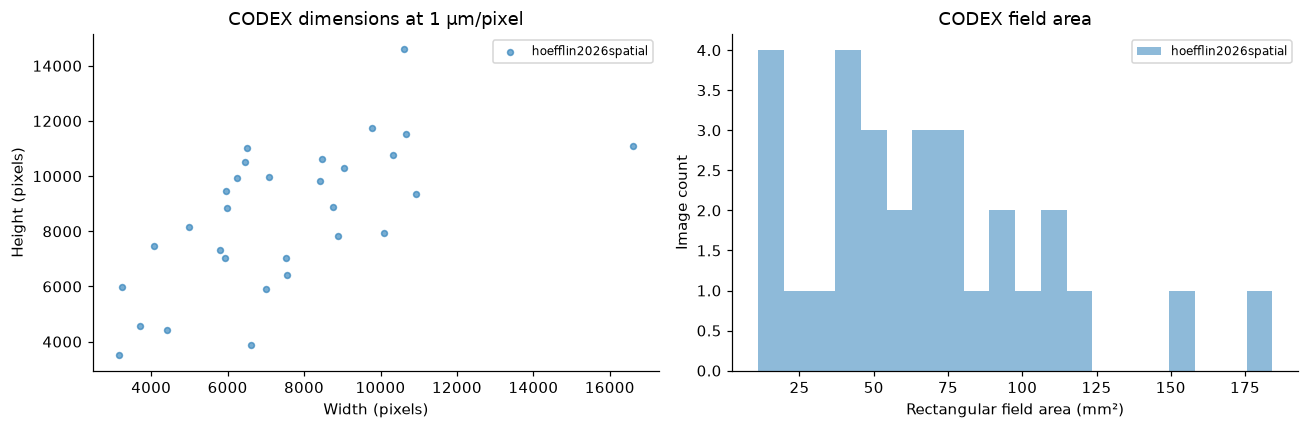

In [5]:
hoefflin_store_rows, hoefflin_image_rows = [], []
for name, root in hoefflin_ROOTS.items():
    for modality in ['codex', 'he']:
        for folder in sorted((root / modality).glob('*/images')):
            stores = sorted(folder.glob('*.ome.zarr'))
            hoefflin_store_rows.append(dict(dataset=name, modality=modality, resolution=folder.parent.name, stores=len(stores)))
            if folder.parent.name != '1_0mpp':
                continue
            for store in stores:
                meta = json.loads((store / 'zarr.json').read_text())['attributes']['ome']
                ms = meta['multiscales'][0]
                level = ms['datasets'][0]
                array_meta = json.loads((store / level['path'] / 'zarr.json').read_text())
                dims = dict(zip([a['name'] for a in ms['axes']], array_meta['shape']))
                scale = next(v['scale'] for v in level['coordinateTransformations'] if v['type'] == 'scale')
                scales = dict(zip([a['name'] for a in ms['axes']], scale))
                hoefflin_image_rows.append(dict(dataset=name, modality=modality, tissue_id=store.name.removesuffix('.ome.zarr'),
                    channels=dims.get('c', 1), height=dims['y'], width=dims['x'], dtype=array_meta['data_type'],
                    field_area_mm2=dims['y']*scales['y']*dims['x']*scales['x']/1e6,
                    uncompressed_GiB=int(np.prod(array_meta['shape']))*np.dtype(array_meta['data_type']).itemsize/2**30,
                    path=str(store)))
hoefflin_store_inventory = pd.DataFrame(hoefflin_store_rows)
hoefflin_images = pd.DataFrame(hoefflin_image_rows)
display(hoefflin_store_inventory)
display(hoefflin_images.groupby(['dataset', 'modality'])[['height', 'width', 'channels', 'field_area_mm2', 'uncompressed_GiB']].agg(['min', 'median', 'max']))
for name, data in hoefflin_tables.items():
    local = hoefflin_images.loc[hoefflin_images.dataset.eq(name)]
    codex_ids = set(local.loc[local.modality.eq('codex'), 'tissue_id'])
    he_ids = set(local.loc[local.modality.eq('he'), 'tissue_id'])
    metadata_ids = set(data['tissues'].loc[data['tissues'].modality.eq('codex'), 'tissue_id'])
    availability_ids = set(data['availability'].index)
    print(f'\n{name}: local paired stores={len(codex_ids & he_ids)}')
    for label, ids in [('CODEX metadata without local store', metadata_ids-codex_ids),
                       ('Local CODEX store without metadata', codex_ids-metadata_ids),
                       ('Channel-table IDs without CODEX metadata', availability_ids-metadata_ids),
                       ('CODEX metadata without channel-table row', metadata_ids-availability_ids)]:
        print(f'  {label}: {len(ids)}; examples={sorted(map(str, ids))[:5]}')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in hoefflin_DATASETS:
    subset = hoefflin_images.loc[hoefflin_images.dataset.eq(name) & hoefflin_images.modality.eq('codex')]
    axes[0].scatter(subset.width, subset.height, label=name, alpha=0.6, s=15)
    axes[1].hist(subset.field_area_mm2, bins=20, alpha=0.5, label=name)
axes[0].set(xlabel='Width (pixels)', ylabel='Height (pixels)', title='CODEX dimensions at 1 µm/pixel')
axes[1].set(xlabel='Rectangular field area (mm²)', ylabel='Image count', title='CODEX field area')
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Representative CODEX crop
The first sorted tissue is shown; this central crop is not a representative biological sample. Intensities are stretched independently to the 1st–99th percentiles and are not quantitative expression comparisons.


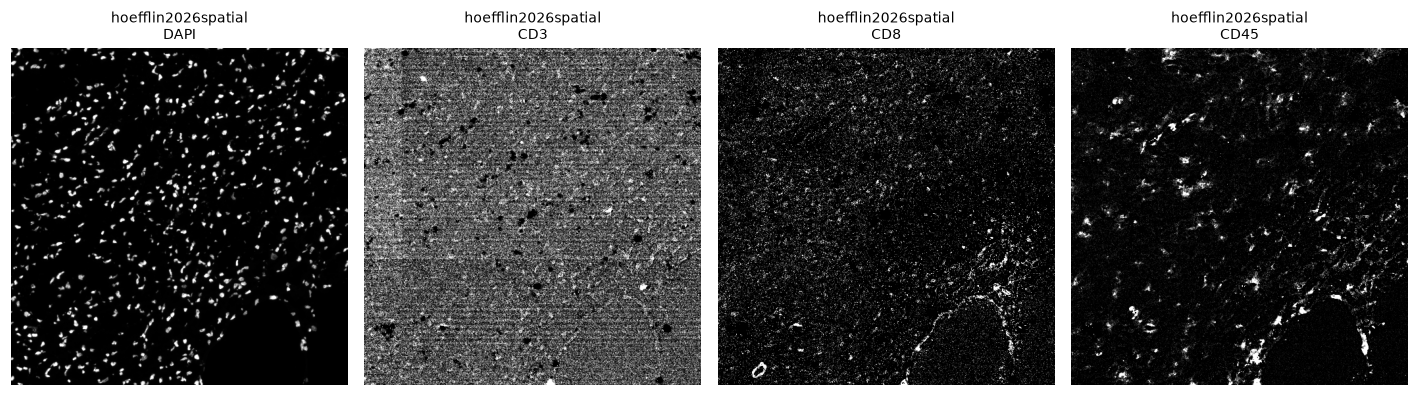

,dataset,tissue_id,channel,crop_y,crop_x,mean,std,p01,median,p99,zero_fraction
0,hoefflin2026spatial,hoefflin2026spatial_almistmp_0000,DAPI,1496,1320,540.868320,1368.251151,91.0,133.0,7302.0,0.000000
1,hoefflin2026spatial,hoefflin2026spatial_almistmp_0000,CD3,1496,1320,15.302166,37.085982,0.0,14.0,43.0,0.053715
2,hoefflin2026spatial,hoefflin2026spatial_almistmp_0000,CD8,1496,1320,4.112862,129.297995,0.0,0.0,41.0,0.716862
3,hoefflin2026spatial,hoefflin2026spatial_almistmp_0000,CD45,1496,1320,16.070709,73.473054,0.0,0.0,236.0,0.524277


In [6]:
hoefflin_CROP_SIZE = 512
hoefflin_preview_stats = []
fig, axes = plt.subplots(1, 4, figsize=(13, 4), squeeze=False)
for row, name in enumerate(hoefflin_DATASETS):
    path = Path(hoefflin_images.loc[hoefflin_images.dataset.eq(name) & hoefflin_images.modality.eq('codex')].sort_values('tissue_id').iloc[0].path)
    group = zarr.open_group(str(path), mode='r')
    ome = group.attrs['ome']
    ms = ome['multiscales'][0]
    assert [a['name'] for a in ms['axes']] == ['c', 'y', 'x'], 'Expected CYX image axes'
    array = group[ms['datasets'][0]['path']]
    labels = [ch['label'] for ch in ome['omero']['channels']]
    chosen = []
    for alternatives in [('DAPI', 'DRAQ5', 'Hoechst2', 'HOECHST2'), ('CD3',), ('CD8',), ('CD68', 'CD45')]:
        idx = next((labels.index(label) for label in alternatives if label in labels and labels.index(label) not in chosen), None)
        if idx is None: idx = next(i for i in range(len(labels)) if i not in chosen)
        chosen.append(idx)
    y0, x0 = max(0, (array.shape[1]-hoefflin_CROP_SIZE)//2), max(0, (array.shape[2]-hoefflin_CROP_SIZE)//2)
    for col, idx in enumerate(chosen):
        crop = np.asarray(array[idx, y0:y0+hoefflin_CROP_SIZE, x0:x0+hoefflin_CROP_SIZE])
        lo, hi = np.percentile(crop, [1, 99])
        axes[row, col].imshow(crop, cmap='gray', vmin=lo, vmax=max(hi, lo+1))
        axes[row, col].set_title(f'{name}\n{labels[idx]}', fontsize=9)
        axes[row, col].axis('off')
        hoefflin_preview_stats.append(dict(dataset=name, tissue_id=path.name.removesuffix('.ome.zarr'), channel=labels[idx],
            crop_y=y0, crop_x=x0, mean=float(crop.mean()), std=float(crop.std()),
            p01=lo, median=float(np.median(crop)), p99=hi, zero_fraction=float((crop == 0).mean())))
plt.tight_layout()
plt.show()
display(pd.DataFrame(hoefflin_preview_stats))

## Available cell annotations
Counts and cell-type composition use the supplied `metadata/cells.parquet`. No segmentation or cell calling is performed. Tissue-level cell counts are not independent patient replicates. The annotation table has no coordinate columns; spatial cell locations can be recovered from the separate instance masks (see the H&E map below).


,missing_percent
tissue_id,0.0
cell_id,0.0
cell_type,0.0
cell_type_atlas,0.0


,cells
count,30.000000
mean,81607.066667
std,49625.231868
min,7556.000000
25%,47213.750000
50%,72371.000000
75%,105774.000000
max,194807.000000


,cells,percent
cell_type,,
cAC1,556310,22.723114
cOPC,425776,17.391304
low,308700,12.609202
excluded,299018,12.213730
Mac,217526,8.885097
cUndiff,134370,5.488495
cAC2,104100,4.252083
Oligo,103796,4.239666
Vasc,100687,4.112675


,cells,percent
cell_type_atlas,,
Tumor,1301883,53.176890
Unknown,814939,33.287109
Myeloid,217836,8.897759
Vessel / Endo.,100687,4.112675
CD4 T cell,8131,0.332120
CD8 T cell,4664,0.190506
B cell,72,0.002941


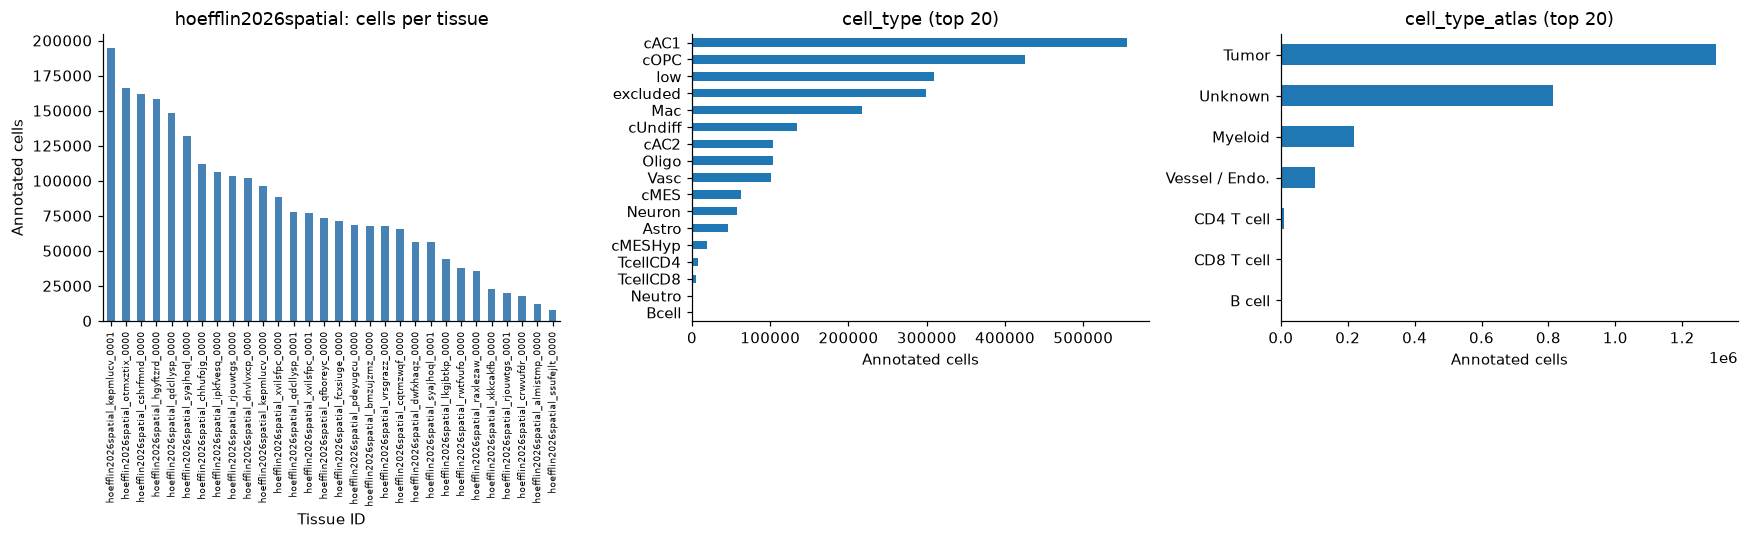

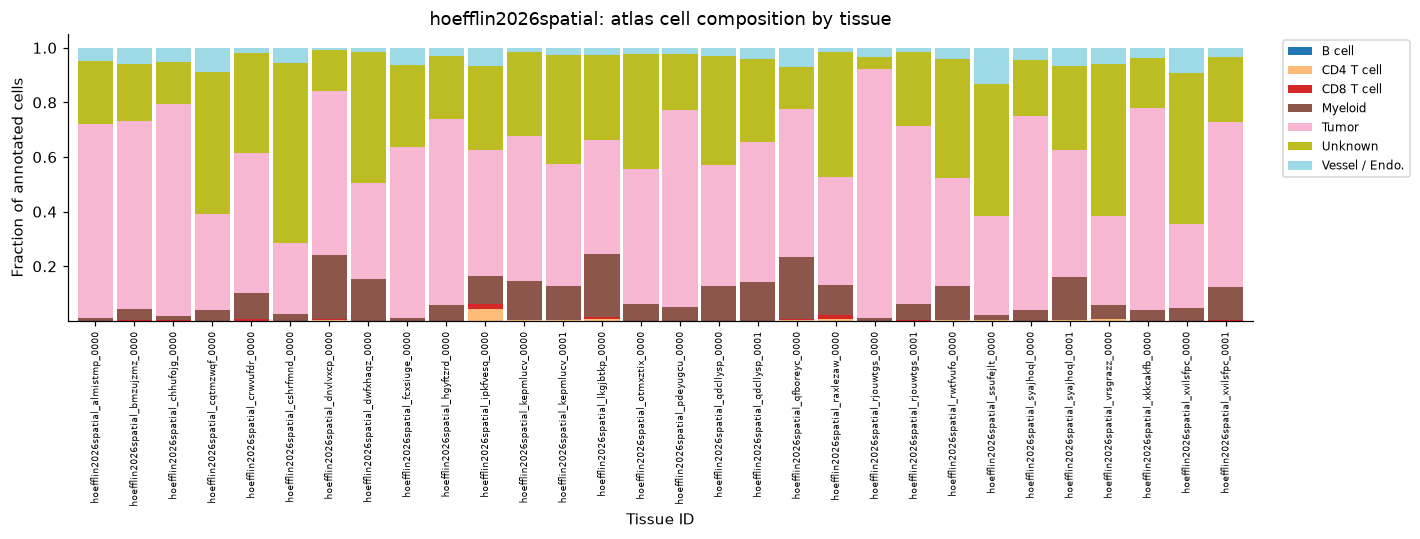

,annotated_cells,annotated_tissues,median_cells_per_tissue,duplicate_tissue_cell_ids,tissues_absent_from_metadata
dataset,,,,,
hoefflin2026spatial,2448212,30,72371.0,0,0


In [7]:
hoefflin_cell_summaries = []
for name, root in hoefflin_ROOTS.items():
    path = root / 'metadata/cells.parquet'
    if not path.exists():
        print(f'{name}: cell annotations unavailable')
        continue
    cells = pd.read_parquet(path)
    counts = cells.groupby('tissue_id').size().rename('cells').sort_values(ascending=False)
    hoefflin_cell_summaries.append(dict(dataset=name, annotated_cells=len(cells), annotated_tissues=len(counts),
        median_cells_per_tissue=counts.median(), duplicate_tissue_cell_ids=int(cells.duplicated(['tissue_id', 'cell_id']).sum()),
        tissues_absent_from_metadata=len(set(counts.index)-set(hoefflin_tables[name]['tissues'].tissue_id))))
    display(cells.isna().mean().mul(100).rename('missing_percent').to_frame())
    display(counts.describe().to_frame())
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    counts.plot.bar(ax=axes[0], color='steelblue')
    axes[0].set(title=f'{name}: cells per tissue', xlabel='Tissue ID', ylabel='Annotated cells')
    axes[0].tick_params(axis='x', labelsize=6)
    for ax, field in zip(axes[1:], ['cell_type', 'cell_type_atlas']):
        labels = cells[field].fillna('(missing)').value_counts()
        display(labels.rename('cells').to_frame().assign(percent=lambda x: 100*x.cells/len(cells)))
        labels.head(20).sort_values().plot.barh(ax=ax)
        ax.set(title=f'{field} (top 20)', xlabel='Annotated cells', ylabel='')
    plt.tight_layout()
    plt.show()
    composition = pd.crosstab(cells.tissue_id, cells.cell_type_atlas.fillna('(missing)'), normalize='index')
    composition.plot.bar(stacked=True, figsize=(13, 5), width=0.9, colormap='tab20')
    plt.ylabel('Fraction of annotated cells')
    plt.title(f'{name}: atlas cell composition by tissue')
    plt.xlabel('Tissue ID')
    plt.xticks(fontsize=6)
    plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
    plt.tight_layout()
    plt.show()
    del cells
if hoefflin_cell_summaries:
    display(pd.DataFrame(hoefflin_cell_summaries).set_index('dataset'))

## H&E cell type map — hoefflin2026spatial

Show the complete H&E image with supplied atlas cell labels using the matching `1_0mpp` instance mask. The overview is downsampled to approximately 1600 pixels on its longest side before plotting. No ROI, crops, or additional high-resolution H&E export. The figure is saved under `result/figures/`, and cell counts under `result/`. Image/mask dimensions and cell IDs are checked. These are supplied annotations, not H&E predictions; alignment relies on the supplied `exact` metadata.


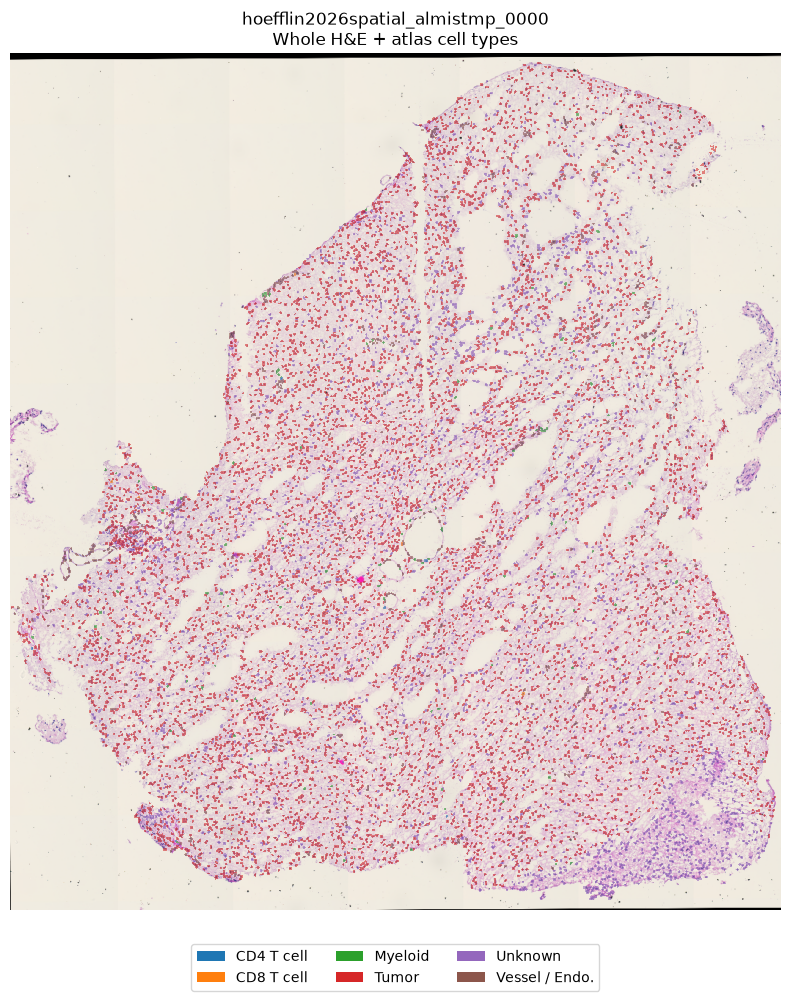

Whole-image overview saved to /lustre/scratch124/cellgen/bayraktar/ll20/project/Embryo_Hist2Pheno/toturial/spora/result/figures/hoefflin2026spatial_HE_cell_type_map.png
Matched annotated cell IDs in mask: 11,716; unmatched nonzero IDs: 0
Transparent regions: background or cells without a matching annotation. Colors come from supplied cell annotations, not H&E predictions.


,annotated_cells
cell_type_atlas,
Tumor,8329
Unknown,2698
Vessel / Endo.,550
Myeloid,127
CD4 T cell,6
CD8 T cell,6


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import zarr
from IPython.display import display

hemap_root = Path('/lustre/scratch127/cellgen/cellgeni/tickets/REQ-82797/data/hoefflin2026spatial/hoefflin2026spatial')
hemap_tissue = 'hoefflin2026spatial_almistmp_0000'
hemap_meta = pd.read_parquet(hemap_root / 'metadata/tissues.parquet')
hemap_rows = hemap_meta.loc[hemap_meta.tissue_id.eq(hemap_tissue)]
assert {'he', 'codex'}.issubset(set(hemap_rows.modality))
assert hemap_rows.alignment.eq('exact').all(), 'Requires exact modality alignment'
hemap_cells = pd.read_parquet(hemap_root / 'metadata/cells.parquet', filters=[('tissue_id', '=', hemap_tissue)])
assert not hemap_cells.cell_id.duplicated().any()
hemap_cells = hemap_cells.sort_values('cell_id')
with np.load(hemap_root / 'segmentations/1_0mpp/cell_masks/instances' / f'{hemap_tissue}.npz', allow_pickle=False) as hemap_file:
    hemap_instances = hemap_file['mask']
hemap_group = zarr.open_group(str(hemap_root / 'he/1_0mpp/images' / f'{hemap_tissue}.ome.zarr'), mode='r')
hemap_ms = hemap_group.attrs['ome']['multiscales'][0]
assert [axis['name'] for axis in hemap_ms['axes']] == ['c', 'y', 'x']
hemap_array = hemap_group[hemap_ms['datasets'][0]['path']]
assert hemap_array.shape == (3, *hemap_instances.shape), 'Image and mask dimensions must agree'
hemap_labels = hemap_cells.cell_type_atlas.fillna('(missing)')
hemap_types = sorted(hemap_labels.unique())
hemap_palette = dict(zip(hemap_types, plt.get_cmap('tab10').colors[:len(hemap_types)]))
hemap_ids = hemap_cells.cell_id.to_numpy()
hemap_present_ids = np.unique(hemap_instances)
hemap_positions = np.searchsorted(hemap_ids, hemap_present_ids)
hemap_matched = (hemap_present_ids != 0) & (hemap_positions < len(hemap_ids))
hemap_matched[hemap_matched] &= hemap_ids[hemap_positions[hemap_matched]] == hemap_present_ids[hemap_matched]
hemap_codes = np.zeros(len(hemap_present_ids), dtype=np.uint8)
hemap_codes[hemap_matched] = pd.Categorical(hemap_labels.iloc[hemap_positions[hemap_matched]], categories=hemap_types).codes + 1
hemap_type_mask = np.empty(hemap_instances.shape, dtype=np.uint8)
for hemap_y in range(0, hemap_instances.shape[0], 256):
    hemap_slice = slice(hemap_y, hemap_y + 256)
    hemap_type_mask[hemap_slice] = hemap_codes[np.searchsorted(hemap_present_ids, hemap_instances[hemap_slice])]
hemap_lut = np.zeros((len(hemap_types)+1, 4))
for hemap_i, hemap_type in enumerate(hemap_types, 1):
    hemap_lut[hemap_i] = [*hemap_palette[hemap_type], 0.55]
# Display the complete image at the previous overview resolution; no ROI.
hemap_stride = max(1, int(np.ceil(max(hemap_instances.shape) / 1600)))
hemap_overview = np.moveaxis(np.asarray(hemap_array[:, ::hemap_stride, ::hemap_stride]), 0, -1)
fig, ax = plt.subplots(figsize=(9, 10))
ax.imshow(hemap_overview)
ax.imshow(hemap_lut[hemap_type_mask[::hemap_stride, ::hemap_stride]], interpolation='nearest')
ax.axis('off')
ax.set_title(f'{hemap_tissue}\nWhole H&E + atlas cell types')
fig.legend(handles=[Patch(facecolor=hemap_palette[t], label=t) for t in hemap_types],
           loc='lower center', ncol=3)
fig.tight_layout(rect=(0, 0.07, 1, 1))
hemap_result_dir = Path('/lustre/scratch124/cellgen/bayraktar/ll20/project/Embryo_Hist2Pheno/toturial/spora/result')
hemap_figure_dir = hemap_result_dir / 'figures'
hemap_figure_dir.mkdir(parents=True, exist_ok=True)
hemap_output = hemap_figure_dir / 'hoefflin2026spatial_HE_cell_type_map.png'
fig.savefig(hemap_output, dpi=160, bbox_inches='tight')
plt.show()
print(f'Whole-image overview saved to {hemap_output}')
print(f'Matched annotated cell IDs in mask: {hemap_matched.sum():,}; unmatched nonzero IDs: {((hemap_present_ids != 0) & ~hemap_matched).sum():,}')
print('Transparent regions: background or cells without a matching annotation. Colors come from supplied cell annotations, not H&E predictions.')
hemap_counts = hemap_labels.value_counts().rename('annotated_cells').to_frame()
hemap_counts.to_csv(hemap_result_dir / 'hoefflin2026spatial_cell_type_counts.csv', index_label='cell_type')
display(hemap_counts)
